In [49]:
!pip install xgboost -q

In [50]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error,
    median_absolute_error,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor



In [51]:
def normalize_digits_fa2en(text: str) -> str:

    if text is None:
        return ""
    if isinstance(text, float) and np.isnan(text):
        return ""
    s = str(text)
    trans = str.maketrans("۰۱۲۳۴۵۶۷۸۹٠١٢٣٤٥٦٧٨٩", "01234567890123456789")
    return s.translate(trans)

In [52]:
def normalize_persian_text(text: str) -> str:

    if text is None:
        return ""
    if isinstance(text, float) and np.isnan(text):
        return ""
    s = str(text)
    s = s.replace("\u200c"," ").replace("‌"," ")
    s = s.replace("ي","ی").replace("ك","ک")
    s = normalize_digits_fa2en(s)
    s = s.lower()
    s = re.sub(r"\s+"," ", s).strip()
    return s

In [54]:

def parse_int_from_str(text: str):

    s = normalize_digits_fa2en(text)
    nums = re.findall(r"\d+", s)
    if not nums:
        return np.nan
    main = max(nums, key=len)
    try:
        return int(main)
    except Exception:
        return np.nan


try:
    df = pd.read_csv("cars_features_merged_no_negotiable.csv", encoding="utf-8-sig")
    print("[INFO] CSV loaded with utf-8-sig")
except Exception as e:
    print("[WARN] utf-8-sig failed, trying default encoding. Error:", e)
    df = pd.read_csv("cars_features_merged_no_negotiable.csv")
    print("[INFO] CSV loaded with default encoding")

print("col s:", list(df.columns))

assert "price_raw" in df.columns, "col price_raw no exist ."
assert "price" in df.columns, "don exist price in this raw"


dedup_subset = [c for c in ["title", "year_raw", "mileage_km", "price_raw"] if c in df.columns]
if dedup_subset:
    before_dedup = len(df)
    df = df.drop_duplicates(subset=dedup_subset, keep="first").copy()
    print(f"[INFO] duplicate: {before_dedup - len(df)}")

df["price_raw_str"] = df["price_raw"].fillna("").astype(str)
df["price_raw_norm"] = df["price_raw_str"].apply(normalize_persian_text)

mask_tavafog = df["price_raw_norm"].str.contains("توافق")
print("tavafoghi del:", int(mask_tavafog.sum()))
df = df.loc[~mask_tavafog].copy()


df["price_str"] = df["price"].fillna("").astype(str)
df["price_num"] = df["price_str"].apply(parse_int_from_str).astype("float64")
df["price_raw_num"] = df["price_raw_str"].apply(parse_int_from_str).astype("float64")

df["price_final"] = df["price_num"]
mask_missing = df["price_final"].isna() | (df["price_final"] <= 0)
df.loc[mask_missing, "price_final"] = df.loc[mask_missing, "price_raw_num"]

before_drop = len(df)
df = df[df["price_final"].notna() & (df["price_final"] > 0)].copy()
after_drop = len(df)
print("tavafoghi price del:", before_drop - after_drop)

print(df["price_final"].describe().apply(lambda x: f"{x:,.0f}"))


df["price_final_million"] = df["price_final"] / 1_000_000.0

print("\nprice_final_million (milion):")
print(df["price_final_million"].describe().apply(lambda x: f"{x:,.3f}"))

q_low, q_hi = df["price_final_million"].quantile([0.01, 0.99])
df = df[(df["price_final_million"] >= q_low) & (df["price_final_million"] <= q_hi)].copy()

print(df["price_final_million"].describe().apply(lambda x: f"{x:,.3f}"))
print("shape", df.shape)


print(df.select_dtypes(include=[np.number]).isna().sum().sum())




TARGET_COL = "price_final_million"

numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
exclude_cols = [
    TARGET_COL,
    "price_final",
    "price_num",
    "price_raw_num",
]

feature_cols = [c for c in numeric_cols if c not in exclude_cols]

X = df[feature_cols].copy()
y = df[TARGET_COL].astype(float).copy()



price_bins = np.quantile(y, [0, 1/3, 2/3, 1])

y_class = np.digitize(y, price_bins[1:-1], right=False)

X_train, X_test, y_train, y_test, y_class_train, y_class_test = train_test_split(
    X, y, y_class, test_size=0.2, random_state=42
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)



metrics_results = {}
trained_models = {}

[INFO] CSV loaded with utf-8-sig
col s: ['source', 'title', 'body_status', 'engine_status', 'chassis_status', 'year_raw', 'price_raw', 'price', 'mileage_km', 'text_all', 'درب رنگ', 'درب تعویض', 'درب بدون رنگ', 'کاپوت تعویض', 'کاپوت بدون رنگ', 'درب صندوق رنگ', 'درب صندوق بدون رنگ', 'شاسی ضرب خوردگی', 'شاسی پلمپ', 'شاسی سالم', 'سقف رنگ', 'سقف بدون رنگ', 'ستون ها سالم', 'ستون ها ضرب دیدگی', 'گلگیر رنگ شدگی', 'گلگیر بدون رنگ', 'گلگیر تعویض', 'فنی سالم', 'فنی نیاز به تعمیر', 'فنی تعمیر شده', 'گیربکس سالم', 'گیر بکس نیاز به تعمیر', 'یک لکه رنگ', 'دو لکه رنگ', 'دور رنگ']
[INFO] duplicate: 2309
tavafoghi del: 0
tavafoghi price del: 20
count               11,353
mean         1,223,641,893
std         39,452,336,417
min                     20
25%            300,000,000
50%            525,000,000
75%            870,000,000
max      4,200,000,000,000
Name: price_final, dtype: object

price_final_million (milion):
count       11,353.000
mean         1,223.642
std         39,452.336
min             

Fitting 5 folds for each of 20 candidates, totalling 100 fits

 best hyper param for ElasticNet:
{'model__l1_ratio': np.float64(1.0), 'model__alpha': np.float64(1.3738237958832638)}

=== ElasticNet (milion) ===
R2        : 0.9880
MAE       : 37.020 milion
RMSE      : 88.687 milion
MSE       : 7865.407
MAPE      : 15.3942
MedAE     : 6.565 milion
Accuracy  : 0.9677
Precision : 0.9684 (macro)
Recall    : 0.9681 (macro)
F1-score  : 0.9680 (macro)

=== LinearRegression (milion) ===
R2        : 0.9882
MAE       : 38.466 milion
RMSE      : 87.967 milion
MSE       : 7738.210
MAPE      : 14.9628
MedAE     : 8.333 milion
Accuracy  : 0.9650
Precision : 0.9658 (macro)
Recall    : 0.9655 (macro)
F1-score  : 0.9653 (macro)
Fitting 3 folds for each of 20 candidates, totalling 60 fits

 best hyper param for XGBoost:
{'model__subsample': 0.8, 'model__reg_lambda': 10, 'model__n_estimators': 400, 'model__max_depth': 6, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}

=== XGBoost (milion) =

,R2,MAE,MSE,RMSE,MAPE,MedAE,ACC,Precision,Recall,F1
ElasticNet,0.987967,37.020433,7865.406777,88.687129,15.394166,6.565418,0.967655,0.968422,0.968105,0.967973
LinearRegression,0.988162,38.465512,7738.209732,87.967095,14.962772,8.332684,0.964960,0.965820,0.965483,0.965313
XGBoost,0.997832,8.915665,1417.263814,37.646564,0.508246,1.396713,0.996406,0.996431,0.996483,0.996446
RandomForest,0.999745,1.235559,166.451528,12.901610,0.229932,0.247105,0.989668,0.989857,0.989848,0.989771


,R2,MAE,MSE,RMSE,MAPE,MedAE
ElasticNet,0.987967,37.020433,7865.406777,88.687129,15.394166,6.565418
LinearRegression,0.988162,38.465512,7738.209732,87.967095,14.962772,8.332684
XGBoost,0.997832,8.915665,1417.263814,37.646564,0.508246,1.396713
RandomForest,0.999745,1.235559,166.451528,12.901610,0.229932,0.247105


,ACC,Precision,Recall,F1
ElasticNet,0.967655,0.968422,0.968105,0.967973
LinearRegression,0.964960,0.965820,0.965483,0.965313
XGBoost,0.996406,0.996431,0.996483,0.996446
RandomForest,0.989668,0.989857,0.989848,0.989771


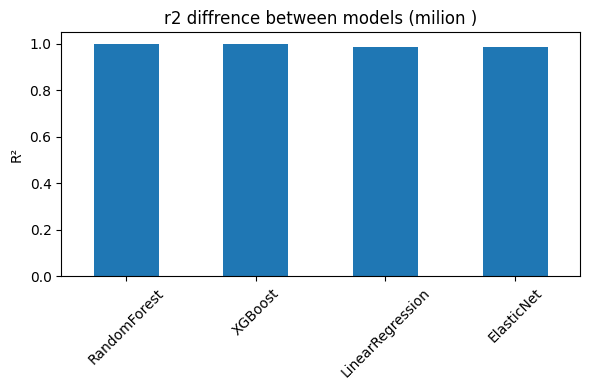

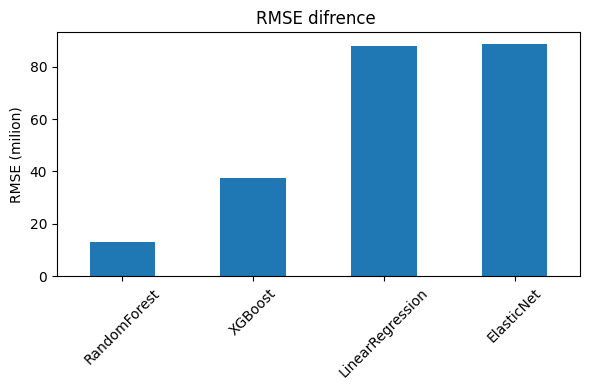

real sample for test 


,price,mileage_km,درب رنگ,درب تعویض,درب بدون رنگ,کاپوت تعویض,کاپوت بدون رنگ,درب صندوق رنگ,درب صندوق بدون رنگ,شاسی ضرب خوردگی,...,گلگیر بدون رنگ,گلگیر تعویض,فنی سالم,فنی نیاز به تعمیر,فنی تعمیر شده,گیربکس سالم,گیر بکس نیاز به تعمیر,یک لکه رنگ,دو لکه رنگ,دور رنگ
9240,450000000.0,75000.0,0,0,0,0,0,0,0,0,...,0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


real price : 450.000
perdict for model(milion toman) 
ElasticNet: 438.805
LinearRegression: 432.013
XGBoost: 450.226
RandomForest: 449.629


In [55]:
def evaluate_and_store(model_name, y_true, y_pred, y_class_true, y_class_pred):

    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    med_ae = median_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)


    y_true_safe = np.where(np.abs(y_true) < 1, 1, y_true)
    mape = np.mean(np.abs((y_true - y_pred) / y_true_safe))


    acc = accuracy_score(y_class_true, y_class_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_class_true, y_class_pred, average="macro", zero_division=0
    )

    metrics_results[model_name] = {
        "R2": r2,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "MAPE": mape,
        "MedAE": med_ae,
        "ACC": acc,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    }

    print(f"\n=== {model_name} (milion) ===")
    print(f"R2        : {r2:.4f}")
    print(f"MAE       : {mae:.3f} milion")
    print(f"RMSE      : {rmse:.3f} milion")
    print(f"MSE       : {mse:.3f}")
    print(f"MAPE      : {mape:.4f}")
    print(f"MedAE     : {med_ae:.3f} milion")
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {precision:.4f} (macro)")
    print(f"Recall    : {recall:.4f} (macro)")
    print(f"F1-score  : {f1:.4f} (macro)")



try:
    elastic_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", ElasticNet(max_iter=10000, random_state=42))
    ])

    param_dist_elastic = {
        "model__alpha": np.logspace(-4, 2, 30),
        "model__l1_ratio": np.linspace(0, 1, 20),
    }

    elastic_search = RandomizedSearchCV(
        estimator=elastic_pipe,
        param_distributions=param_dist_elastic,
        n_iter=20,
        scoring="neg_root_mean_squared_error",
        cv=5,
        random_state=42,
        n_jobs=-1,
        verbose=1,
    )

    elastic_search.fit(X_train, y_train)

    print("\n best hyper param for ElasticNet:")
    print(elastic_search.best_params_)

    best_elastic = elastic_search.best_estimator_
    trained_models["ElasticNet"] = best_elastic

    y_pred_elastic = best_elastic.predict(X_test)

    y_class_pred_elastic = np.digitize(y_pred_elastic, price_bins[1:-1], right=False)

    evaluate_and_store("ElasticNet", y_test, y_pred_elastic, y_class_test, y_class_pred_elastic)

except Exception as e:
    print("[ERROR] ElasticNet training failed:", e)


try:
    lin_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ])

    lin_pipe.fit(X_train, y_train)
    trained_models["LinearRegression"] = lin_pipe

    y_pred_lin = lin_pipe.predict(X_test)
    y_class_pred_lin = np.digitize(y_pred_lin, price_bins[1:-1], right=False)

    evaluate_and_store("LinearRegression", y_test, y_pred_lin, y_class_test, y_class_pred_lin)

except Exception as e:
    print("[ERROR] LinearRegression training failed:", e)


try:
    xgb_base = XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        tree_method="hist",
    )

    xgb_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", xgb_base),
    ])

    param_dist_xgb = {
        "model__n_estimators": [200, 400, 800],
        "model__max_depth": [3, 4, 6, 8],
        "model__learning_rate": [0.01, 0.05, 0.1],
        "model__subsample": [0.8, 1.0],
        "model__colsample_bytree": [0.8, 1.0],
        "model__reg_lambda": [1, 5, 10],
    }

    xgb_search = RandomizedSearchCV(
        estimator=xgb_pipe,
        param_distributions=param_dist_xgb,
        n_iter=20,
        scoring="neg_root_mean_squared_error",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=1,
    )

    xgb_search.fit(X_train, y_train)

    print("\n best hyper param for XGBoost:")
    print(xgb_search.best_params_)

    best_xgb = xgb_search.best_estimator_
    trained_models["XGBoost"] = best_xgb

    y_pred_xgb = best_xgb.predict(X_test)
    y_class_pred_xgb = np.digitize(y_pred_xgb, price_bins[1:-1], right=False)

    evaluate_and_store("XGBoost", y_test, y_pred_xgb, y_class_test, y_class_pred_xgb)

except Exception as e:
    print("[ERROR] XGBoost training failed:", e)

try:
    rf_base = RandomForestRegressor(
        random_state=42,
        n_jobs=-1,
    )

    rf_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", rf_base),
    ])

    param_dist_rf = {
        "model__n_estimators": [200, 400, 800],
        "model__max_depth": [None, 5, 10, 20],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", "log2", None],
    }

    rf_search = RandomizedSearchCV(
        estimator=rf_pipe,
        param_distributions=param_dist_rf,
        n_iter=20,
        scoring="neg_root_mean_squared_error",
        cv=3,
        random_state=42,
        n_jobs=-1,
        verbose=1,
    )

    rf_search.fit(X_train, y_train)

    print("\n best hyper param for RandomForest:")
    print(rf_search.best_params_)

    best_rf = rf_search.best_estimator_
    trained_models["RandomForest"] = best_rf

    y_pred_rf = best_rf.predict(X_test)
    y_class_pred_rf = np.digitize(y_pred_rf, price_bins[1:-1], right=False)

    evaluate_and_store("RandomForest", y_test, y_pred_rf, y_class_test, y_class_pred_rf)

except Exception as e:
    print("[ERROR] RandomForest training failed:", e)



if len(metrics_results) == 0:
    print("\n[WARN] no model for train & eval")
else:
    metrics_df = pd.DataFrame(metrics_results).T

    print("evry metrics(Regression + Classification):")
    display(metrics_df)

    reg_cols = ["R2", "MAE", "MSE", "RMSE", "MAPE", "MedAE"]
    cls_cols = ["ACC", "Precision", "Recall", "F1"]


    display(metrics_df[reg_cols])


    display(metrics_df[cls_cols])


    plt.figure(figsize=(6,4))
    metrics_df["R2"].sort_values(ascending=False).plot(kind="bar")
    plt.title("r2 diffrence between models (milion )")
    plt.ylabel("R²")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


    plt.figure(figsize=(6,4))
    metrics_df["RMSE"].sort_values(ascending=True).plot(kind="bar")
    plt.title("RMSE difrence ")
    plt.ylabel("RMSE (milion)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


    try:
        sample_idx = X_test.index[0]
        sample_X = X_test.loc[[sample_idx]]
        sample_y_true = y_test.loc[sample_idx]

        print("real sample for test ")
        display(sample_X)
        print(f"real price : {sample_y_true:.3f}")

        print("perdict for model(milion toman) ")
        for name, model in trained_models.items():
            try:
                pred = model.predict(sample_X)[0]
                print(f"{name}: {pred:.3f}")
            except Exception as e:
                print(f"[ERROR] prediction failed for {name}:", e)

    except Exception as e:
        print("[WARN] do n't choice x_train for model ", e)


In [56]:
if len(trained_models) == 0:
    print("no model train")
else:

    damage_keywords = [
        "شاسی", "سقف", "ستون", "گلگیر", "درب", "کاپوت",
        "فنی", "گیربکس", "گیر بکس", "لکه رنگ", "دور رنگ"
    ]

    def show_feature_importances(model_name, top_n=20):
        if model_name not in trained_models:
            print(f"[WARN] model {model_name}not exist.")
            return

        pipe = trained_models[model_name]
        if "model" not in pipe.named_steps:
            print(f"[WARN]model in pipeline {model_name}، not found model")
            return

        base_model = pipe.named_steps["model"]

        if not hasattr(base_model, "feature_importances_"):
            print(f"[WARN] model {model_name} no feature_importances")
            return

        importances = base_model.feature_importances_
        fi_df = pd.DataFrame({
            "feature": feature_cols,
            "importance": importances
        }).sort_values("importance", ascending=False)

        print(f"{model_name} (Top {top_n})")
        display(fi_df.head(top_n))


        mask_damage = fi_df["feature"].apply(
            lambda f: any(k in f for k in damage_keywords)
        )
        damage_fi = fi_df[mask_damage].head(top_n)

        print(f"{model_name}")
        display(damage_fi)



    show_feature_importances("RandomForest", top_n=25)

    show_feature_importances("XGBoost", top_n=25)

RandomForest (Top 25)


,feature,importance
0,price,9.983736e-01
10,شاسی پلمپ,1.380259e-03
1,mileage_km,1.965273e-04
25,دو لکه رنگ,2.090186e-05
11,شاسی سالم,1.536040e-05
16,گلگیر رنگ شدگی,1.160792e-05
22,گیربکس سالم,1.006638e-06
18,گلگیر تعویض,2.891653e-07
24,یک لکه رنگ,2.438050e-07
19,فنی سالم,1.981271e-07


RandomForest


,feature,importance
10,شاسی پلمپ,1.380259e-03
25,دو لکه رنگ,2.090186e-05
11,شاسی سالم,1.536040e-05
16,گلگیر رنگ شدگی,1.160792e-05
22,گیربکس سالم,1.006638e-06
18,گلگیر تعویض,2.891653e-07
24,یک لکه رنگ,2.438050e-07
19,فنی سالم,1.981271e-07
26,دور رنگ,3.827704e-08
12,سقف رنگ,2.422378e-11


XGBoost (Top 25)


,feature,importance
0,price,9.875653e-01
10,شاسی پلمپ,8.723303e-03
20,فنی نیاز به تعمیر,5.520878e-04
1,mileage_km,5.393674e-04
5,کاپوت تعویض,5.011511e-04
11,شاسی سالم,3.436734e-04
19,فنی سالم,2.992629e-04
16,گلگیر رنگ شدگی,2.417727e-04
18,گلگیر تعویض,2.375959e-04
14,ستون ها سالم,2.086744e-04


XGBoost


,feature,importance
10,شاسی پلمپ,8.723303e-03
20,فنی نیاز به تعمیر,5.520878e-04
5,کاپوت تعویض,5.011511e-04
11,شاسی سالم,3.436734e-04
19,فنی سالم,2.992629e-04
16,گلگیر رنگ شدگی,2.417727e-04
18,گلگیر تعویض,2.375959e-04
14,ستون ها سالم,2.086744e-04
25,دو لکه رنگ,1.639805e-04
22,گیربکس سالم,1.543538e-04


In [65]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split

# --- تنظیمات ورودی ---
target_brand = 'سمند'
target_model = 'ef7'

car_specs = {
    'year_raw': 1400,
    'mileage_km': 307000,
    'شاسی پلمپ': 0,
    'شاسی سالم': 1,
    'شاسی ضرب خوردگی': 0,
    'یک لکه رنگ': 0,
    'دو لکه رنگ': 0,
    'دور رنگ': 0,
    'درب رنگ': 0,
    'گلگیر رنگ شدگی': 0,
    'سقف رنگ': 0,
    'درب صندوق رنگ': 0,
    'کاپوت بدون رنگ': 0,
    'درب بدون رنگ': 0,
    'گلگیر بدون رنگ': 0,
    'سقف بدون رنگ': 0,
    'درب صندوق بدون رنگ': 0,
    'درب تعویض': 0,
    'گلگیر تعویض': 0,
    'کاپوت تعویض': 0,
    'فنی سالم': 1,
    'فنی نیاز به تعمیر': 0,
    'فنی تعمیر شده': 0,
    'گیربکس سالم': 1,
    'گیر بکس نیاز به تعمیر': 0,
    'ستون ها سالم': 1,
    'ستون ها ضرب دیدگی': 0
}

print(f"🔍 Searching for cars: {target_brand} {target_model} ...")

# فیلتر کردن دیتا
mask = df['title'].str.contains(target_brand, na=False)
if target_model:
    mask = mask & df['title'].str.contains(target_model, na=False)

df_filtered = df[mask].copy()
count = len(df_filtered)

if count < 10:
    print(f"❌ Error: Very few data points found ({count} records).")
    print("Suggestion: Clear the specific model name (target_model) to search more broadly.")
else:
    print(f"✅ {count} similar cars found. Training the AI model...")

    # آماده‌سازی ستون‌ها
    numeric_cols = df_filtered.select_dtypes(include=[np.number]).columns.tolist()
    exclude_cols = ["price_final_million", "price_final", "price_num", "price_raw_num", "price", "price_raw"]
    feature_cols = [c for c in numeric_cols if c not in exclude_cols]

    X = df_filtered[feature_cols].copy()
    y = df_filtered["price_final_million"].copy()

    # تعریف محدودیت‌های منطقی
    constraints = {}
    for col in X.columns:
        if col == 'year_raw': constraints[col] = 1
        elif col == 'mileage_km': constraints[col] = -1
        elif any(x in col for x in ['سالم', 'پلمپ', 'بدون']): constraints[col] = 1
        else: constraints[col] = -1

    constraint_list = "(" + ",".join([str(constraints.get(col, 0)) for col in X.columns]) + ")"

    # ساخت و آموزش مدل
    model = XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=6,
        monotone_constraints=constraint_list, n_jobs=-1, random_state=42
    )
    model.fit(X, y)
    print("🎓 Dedicated model trained.")

    # آماده‌سازی ورودی برای پیش‌بینی
    input_df = pd.DataFrame([car_specs])
    for col in feature_cols:
        if col not in input_df.columns:
            input_df[col] = 0
    input_df = input_df[feature_cols]

    try:
        predicted_price = model.predict(input_df)[0]

        print("\n" + "*"*50)
        print(f"🚘 Smart Price Estimation Result")
        print(f"Car: {target_brand} {target_model}")
        print(f"Year: {car_specs['year_raw']} | Mileage: {car_specs['mileage_km']:,} km")
        print("-" * 50)
        print(f"💰 Estimated Price: {predicted_price:,.1f} Million Tomans")
        print("*"*50)

    except Exception as e:
        print(f"Error in calculation: {e}")

🔍 Searching for cars: سمند ef7 ...
✅ 67 similar cars found. Training the AI model...
🎓 Dedicated model trained.

**************************************************
🚘 Smart Price Estimation Result
Car: سمند ef7
Year: 1400 | Mileage: 307,000 km
--------------------------------------------------
💰 Estimated Price: 382.2 Million Tomans
**************************************************
